In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import f_oneway

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("cleaned_wine_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

Column Names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'wine_class']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float

In [4]:
groups = [
    df.loc[df["wine_class"] == cls, "alcohol"].dropna()
    for cls in sorted(df["wine_class"].unique())
]

f_statistic, p_value = f_oneway(*groups)

print("One-Way ANOVA Results")
print("-" * 30)
print("F-statistic:", f_statistic)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("Mean alcohol content differs significantly among the classes.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference in class means.")

One-Way ANOVA Results
------------------------------
F-statistic: 135.07762424279917
P-value: 3.319503795619574e-36

Decision: Reject the null hypothesis.
Mean alcohol content differs significantly among the classes.


In [5]:
X = df.drop(columns=["wine_class"])
y = df["wine_class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Features shape: (178, 13)
Target shape: (178,)

Target classes:
wine_class
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 133
Testing samples: 45
Training target distribution:
wine_class
class_1    53
class_0    44
class_2    36
Name: count, dtype: int64

Testing target distribution:
wine_class
class_1    18
class_0    15
class_2    12
Name: count, dtype: int64


In [7]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [8]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Class": y_test.to_numpy(),
    "Predicted Class": y_pred
})

display(results.head(10))

,Actual Class,Predicted Class
0,class_0,class_0
1,class_1,class_1
2,class_0,class_0
3,class_0,class_0
4,class_1,class_1
5,class_0,class_0
6,class_0,class_0
7,class_1,class_1
8,class_1,class_1
9,class_2,class_2


In [9]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("MODEL EVALUATION")
print("-" * 35)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

MODEL EVALUATION
-----------------------------------
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000


In [10]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



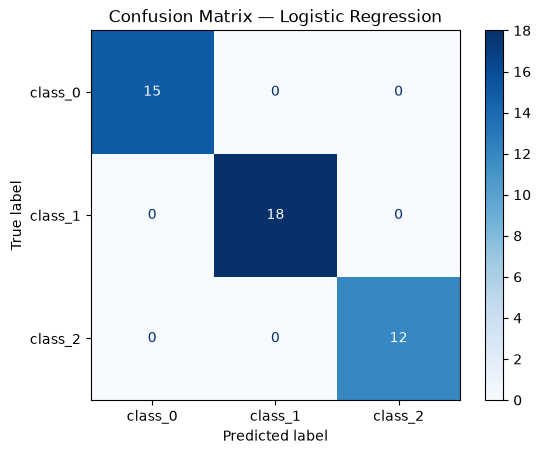

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix — Logistic Regression")
plt.show()

In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Cross-Validation Scores:")
for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nMean CV Accuracy:", round(cv_scores.mean(), 4))
print("CV Accuracy Standard Deviation:", round(cv_scores.std(), 4))

Cross-Validation Scores:
Fold 1: 0.9722
Fold 2: 0.9722
Fold 3: 0.9722
Fold 4: 1.0000
Fold 5: 1.0000

Mean CV Accuracy: 0.9833
CV Accuracy Standard Deviation: 0.0136


In [13]:
summary = pd.DataFrame({
    "Metric": [
        "ANOVA F-statistic",
        "ANOVA P-value",
        "Test Accuracy",
        "Test Macro Precision",
        "Test Macro Recall",
        "Test Macro F1-score",
        "Mean 5-Fold CV Accuracy"
    ],
    "Value": [
        f_statistic,
        p_value,
        accuracy,
        precision,
        recall,
        f1,
        cv_scores.mean()
    ]
})

display(summary)

,Metric,Value
0,ANOVA F-statistic,1.350776e+02
1,ANOVA P-value,3.319504e-36
2,Test Accuracy,1.000000e+00
3,Test Macro Precision,1.000000e+00
4,Test Macro Recall,1.000000e+00
5,Test Macro F1-score,1.000000e+00
6,Mean 5-Fold CV Accuracy,9.833333e-01


In [14]:
results.to_csv("week3_model_predictions.csv", index=False)
summary.to_csv("week3_model_summary.csv", index=False)

print("Week 3 result files saved successfully!")

Week 3 result files saved successfully!


In [15]:
print("WEEK 3 CONCLUSION")
print("-" * 40)

if p_value < 0.05:
    print(
        "ANOVA indicates a statistically significant difference "
        "in mean alcohol content among the wine classes."
    )
else:
    print(
        "ANOVA did not provide sufficient evidence of a difference "
        "in mean alcohol content among the wine classes."
    )

print(f"\nTest accuracy: {accuracy:.2%}")
print(f"Mean cross-validation accuracy: {cv_scores.mean():.2%}")

print(
    "\nThe Logistic Regression model was evaluated using a held-out "
    "test set and five-fold stratified cross-validation."
)

print(
    "Performance results apply to this dataset and evaluation setup; "
    "they do not guarantee the same performance on unseen real-world data."
)

WEEK 3 CONCLUSION
----------------------------------------
ANOVA indicates a statistically significant difference in mean alcohol content among the wine classes.

Test accuracy: 100.00%
Mean cross-validation accuracy: 98.33%

The Logistic Regression model was evaluated using a held-out test set and five-fold stratified cross-validation.
Performance results apply to this dataset and evaluation setup; they do not guarantee the same performance on unseen real-world data.
